# Water Quality Index Prediction using Polynomial Regression

## Objective
Predict the Water Quality Index (WQI) using dissolved oxygen (DO), pH, electrical conductivity (EC), and nitrate.

## Workflow
1. Load and clean the dataset
2. Calculate Weighted Arithmetic WQI
3. Feature engineering
4. Train Linear and Polynomial Regression models
5. Evaluate using R² score


        Import the required library  

In [1]:
import numpy as np
import pandas as pd
import sklearn 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

        Import WQL data 

In [2]:
df = pd.read_excel("WQI DATA.xlsx")
df.head()

,Station\nCode,Monitoring Location,State,Min DO,Max DO,Min pH,Max pH,Min EC,Max EC,Min N,Max N
0,1001.0,RIVER BEAS AT U/S MANALI,HIMACHAL\nPRADESH,7.8,9.2,7.2,8.2,68.0,380.0,0.32,1.15
1,2601.0,RIVER BEAS AT D/S MANALI,HIMACHAL\nPRADESH,7.6,9.0,6.5,8.1,58.0,135.0,0.32,1.87
2,4444.0,RIVER BEAS D/S OF WASTE PROCESSING FACILITY AT...,HIMACHAL\nPRADESH,7.8,8.8,6.7,7.8,62.0,113.0,0.32,1.08
3,4037.0,RIVER BEAS D/S MANALSU NALLAH,HIMACHAL\nPRADESH,7.9,8.9,6.3,8.0,52.0,137.0,0.32,1.74
4,3866.0,RIVER BEAS U/S BEFORE CONF. OF MANALSU NALLAH,HIMACHAL\nPRADESH,7.8,9.1,7.0,7.8,51.0,113.0,0.32,0.97


In [3]:
print(df.shape)

(1104, 11)


In [4]:
df.isnull().sum()

Station\nCode            4
Monitoring Location      1
State                    4
Min DO                   5
Max DO                   5
Min pH                   4
Max pH                   4
Min EC                  38
Max EC                  38
Min N                  188
Max N                  151
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1104 entries, 0 to 1103
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Station
Code         1100 non-null   float64
 1   Monitoring Location  1103 non-null   object 
 2   State                1100 non-null   object 
 3   Min DO               1099 non-null   float64
 4   Max DO               1099 non-null   float64
 5   Min pH               1100 non-null   float64
 6   Max pH               1100 non-null   float64
 7   Min EC               1066 non-null   float64
 8   Max EC               1066 non-null   float64
 9   Min N                916 non-null    float64
 10  Max N                953 non-null    float64
dtypes: float64(9), object(2)
memory usage: 95.0+ KB


        Data cleaning and Handaling 

In [6]:
df = df.drop(['Station\nCode','Monitoring Location','State'], axis=1)  # Since we dont need any categorical column

In [7]:
df.dropna(inplace=True)

In [8]:
df.isna().sum()

Min DO    0
Max DO    0
Min pH    0
Max pH    0
Min EC    0
Max EC    0
Min N     0
Max N     0
dtype: int64

In [9]:
print(df.shape)

(916, 8)


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 916 entries, 0 to 1099
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Min DO  916 non-null    float64
 1   Max DO  916 non-null    float64
 2   Min pH  916 non-null    float64
 3   Max pH  916 non-null    float64
 4   Min EC  916 non-null    float64
 5   Max EC  916 non-null    float64
 6   Min N   916 non-null    float64
 7   Max N   916 non-null    float64
dtypes: float64(8)
memory usage: 64.4 KB


        Applying the Weighted Arithmetic Formula for WQI target column

In [11]:
stv = np.array([6,8.5,1000,45])              # Standard values
stv_1 = [1/s for s in stv]                   # 1/si
k = 1/np.sum(stv_1)                          # k = 1/∑(1/si)
w = [k/x for x in stv]                       # wi = k/si
w_n = np.array([x/sum(w) for x in w])

In [12]:
print(k)
print(w_n)
print(w)

3.2516523919835083
[0.54194207 0.38254734 0.00325165 0.07225894]
[np.float64(0.5419420653305848), np.float64(0.3825473402333539), np.float64(0.0032516523919835084), np.float64(0.07225894204407796)]


In [13]:
iv = np.array([14.6, 7, 0, 0])  # Ideal & standard values
diff = (stv - iv)

def calculating_WQI(row):
    q = 100 * np.abs((row - iv)/diff)  # Quality rating formula 
    return np.dot(q,w_n)

In [14]:
def avg(col1,col2):
    return (col1.to_numpy() + col2.to_numpy())/2           # Averaging columns (max + min)/2

df_final = pd.DataFrame()
df_final['Dissolve Oxygen'] = avg(df['Max DO'],df['Min DO'])
df_final['pH'] = avg(df['Max pH'],df['Min pH'])
df_final['Electrical Conductivity'] = avg(df['Max EC'],df['Min EC'])
df_final['Nitrate'] = avg(df['Max N'],df['Min N'])

In [15]:
wqi = df_final.apply(calculating_WQI,axis=1) # Applying the Weight Arithmetic WQI
df_final["WQI"] = wqi  # target column 
df_final   # Final data for model training and testing 

,Dissolve Oxygen,pH,Electrical Conductivity,Nitrate,WQI
0,8.50,7.70,224.0,0.735,56.483146
1,8.30,7.30,96.5,1.095,47.558562
2,8.30,7.25,87.5,0.700,46.217051
3,8.40,7.15,94.5,1.030,43.091836
4,8.45,7.40,82.0,0.645,49.086656
...,...,...,...,...,...
911,7.55,7.60,260.0,0.580,59.906216
912,6.90,7.55,204.0,0.545,62.703303
913,7.45,7.75,207.5,0.635,64.353615
914,7.30,7.70,11569.0,0.600,67.712450


In [16]:
df_final.head()

,Dissolve Oxygen,pH,Electrical Conductivity,Nitrate,WQI
0,8.50,7.70,224.0,0.735,56.483146
1,8.30,7.30,96.5,1.095,47.558562
2,8.30,7.25,87.5,0.700,46.217051
3,8.40,7.15,94.5,1.030,43.091836
4,8.45,7.40,82.0,0.645,49.086656


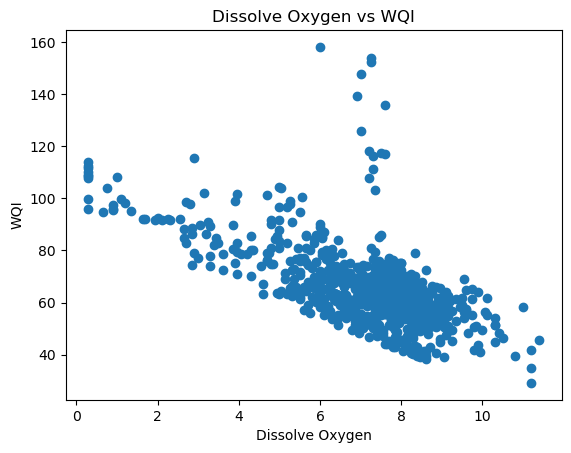

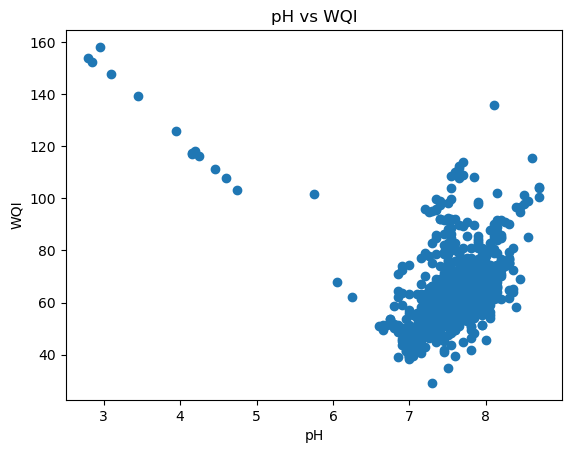

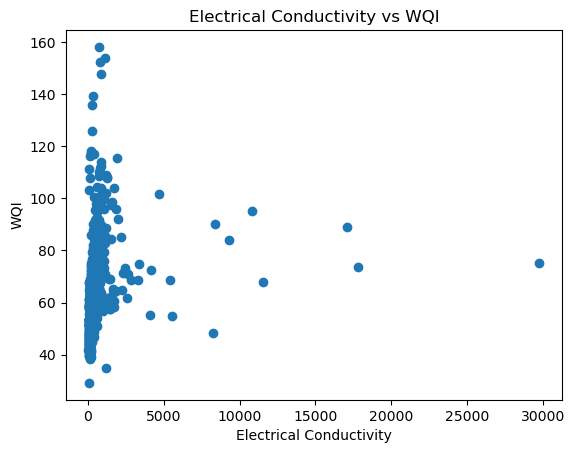

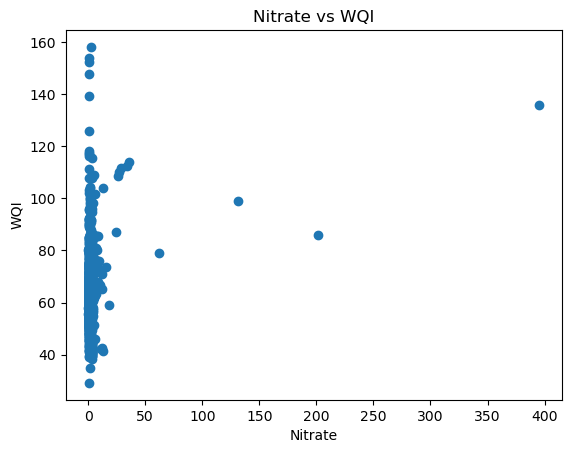

In [17]:
params = ['Dissolve Oxygen','pH','Electrical Conductivity','Nitrate']

for p in params:
    plt.figure()
    plt.scatter(df_final[p], df_final['WQI'])
    plt.xlabel(p)
    plt.ylabel('WQI')
    plt.title(f'{p} vs WQI')
    plt.show()

In [18]:
df_final.corr() # correlation 

,Dissolve Oxygen,pH,Electrical Conductivity,Nitrate,WQI
Dissolve Oxygen,1.000000,0.125713,-0.141784,-0.059051,-0.631991
pH,0.125713,1.000000,0.033634,0.021862,-0.190585
Electrical Conductivity,-0.141784,0.033634,1.000000,-0.002632,0.170111
Nitrate,-0.059051,0.021862,-0.002632,1.000000,0.213149
WQI,-0.631991,-0.190585,0.170111,0.213149,1.000000


In [19]:
x = df_final[['Dissolve Oxygen','pH','Electrical Conductivity','Nitrate']]
print(x.shape)

(916, 4)


In [20]:
y = df_final['WQI']
print(y.shape)

(916,)


    Splitting data into training, testing and validation 

In [21]:
from sklearn.model_selection import train_test_split

x_train,x_temp,y_train,y_temp = train_test_split(x,y,test_size=0.3,random_state=42)

In [22]:
x_test,x_val,y_test,y_val =train_test_split(x_temp,y_temp,test_size=0.5,random_state=42)

### Standard Scaler 

In [23]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
x_val = scaler.transform(x_val)

## Linear Regression 

In [24]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [25]:
print("coefficient",lr.coef_)
print("Intercept",lr.intercept_)

coefficient [-9.03208838 -2.67539187  1.46239958  3.13491058]
Intercept 65.27138486404618


In [26]:
y_train_pred = lr.predict(x_train)
y_test_pred = lr.predict(x_test)
y_val_pred = lr.predict(x_val)

In [27]:
from sklearn.metrics import r2_score # r2_sc
print("Train r2",r2_score(y_train,y_train_pred))
print("Test r2",r2_score(y_test,y_test_pred))
print("Validation",r2_score(y_val,y_val_pred))

Train r2 0.4558914040172364
Test r2 0.5175320266106207
Validation 0.35455821093926787


## Polynomial Regression  Degree = 2

In [34]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)

x_train_poly2 = poly2.fit_transform(x_train)
x_test_poly2 = poly2.transform(x_test)
x_val_poly2 = poly2.transform(x_val)

In [35]:
lr_poly2 = LinearRegression()
lr_poly2.fit(x_train_poly2, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [36]:
y_train_pred2 = lr_poly2.predict(x_train_poly2)
y_test_pred2 = lr_poly2.predict(x_test_poly2)
y_val_pred2 = lr_poly2.predict(x_val_poly2)

In [37]:
print("Polynomial regression Degree = 2")
print("Train R2 :", r2_score(y_train, y_train_pred2))
print("Test R2  :", r2_score(y_test, y_test_pred2))
print("Validation R2 :", r2_score(y_val, y_val_pred2))

Polynomial regression Degree = 2
Train R2 : 0.961418469886502
Test R2  : 0.9537607502122535
Validation R2 : 0.9361474463125543


## Polynomial Regression Degree = 3

In [38]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
x_train_poly3 = poly3.fit_transform(x_train)
x_test_poly3 = poly3.transform(x_test)
x_val_poly3 = poly3.transform(x_val)

In [39]:
lr_poly3 = LinearRegression()
lr_poly3.fit(x_train_poly3, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [40]:
y_train_pred3 = lr_poly3.predict(x_train_poly3)
y_test_pred3 = lr_poly3.predict(x_test_poly3)
y_val_pred3 = lr_poly3.predict(x_val_poly3)

In [41]:
print("Polynomial Regression Degree = 3")
print("Train R2 :", r2_score(y_train, y_train_pred3))
print("Test R2  :", r2_score(y_test, y_test_pred3))
print("Validation R2 :", r2_score(y_val, y_val_pred3))

Polynomial Regression Degree = 3
Train R2 : 0.9878792741821782
Test R2  : 0.9067080488149102
Validation R2 : 0.9583952517910492


        We selected degree 2 because it provides a good balance between model performance and generalization, while degree 3 shows signs of increased overfitting.

# Visualization 

<Axes: >

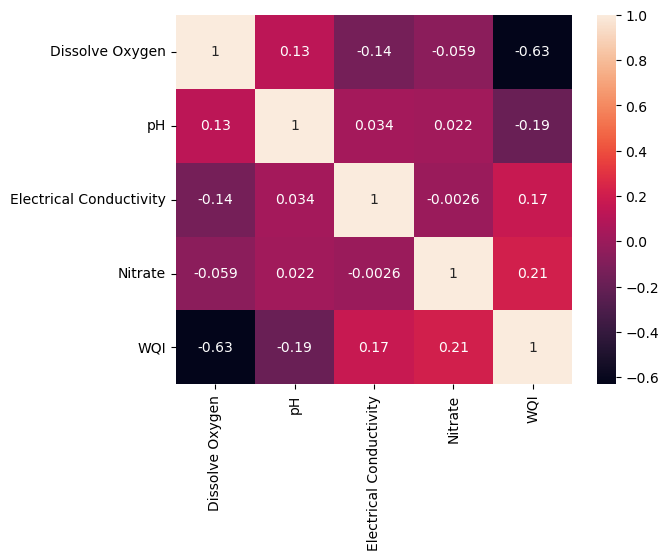

In [42]:
sns.heatmap(df_final.corr(),annot=True)  # correlation Heatmap 

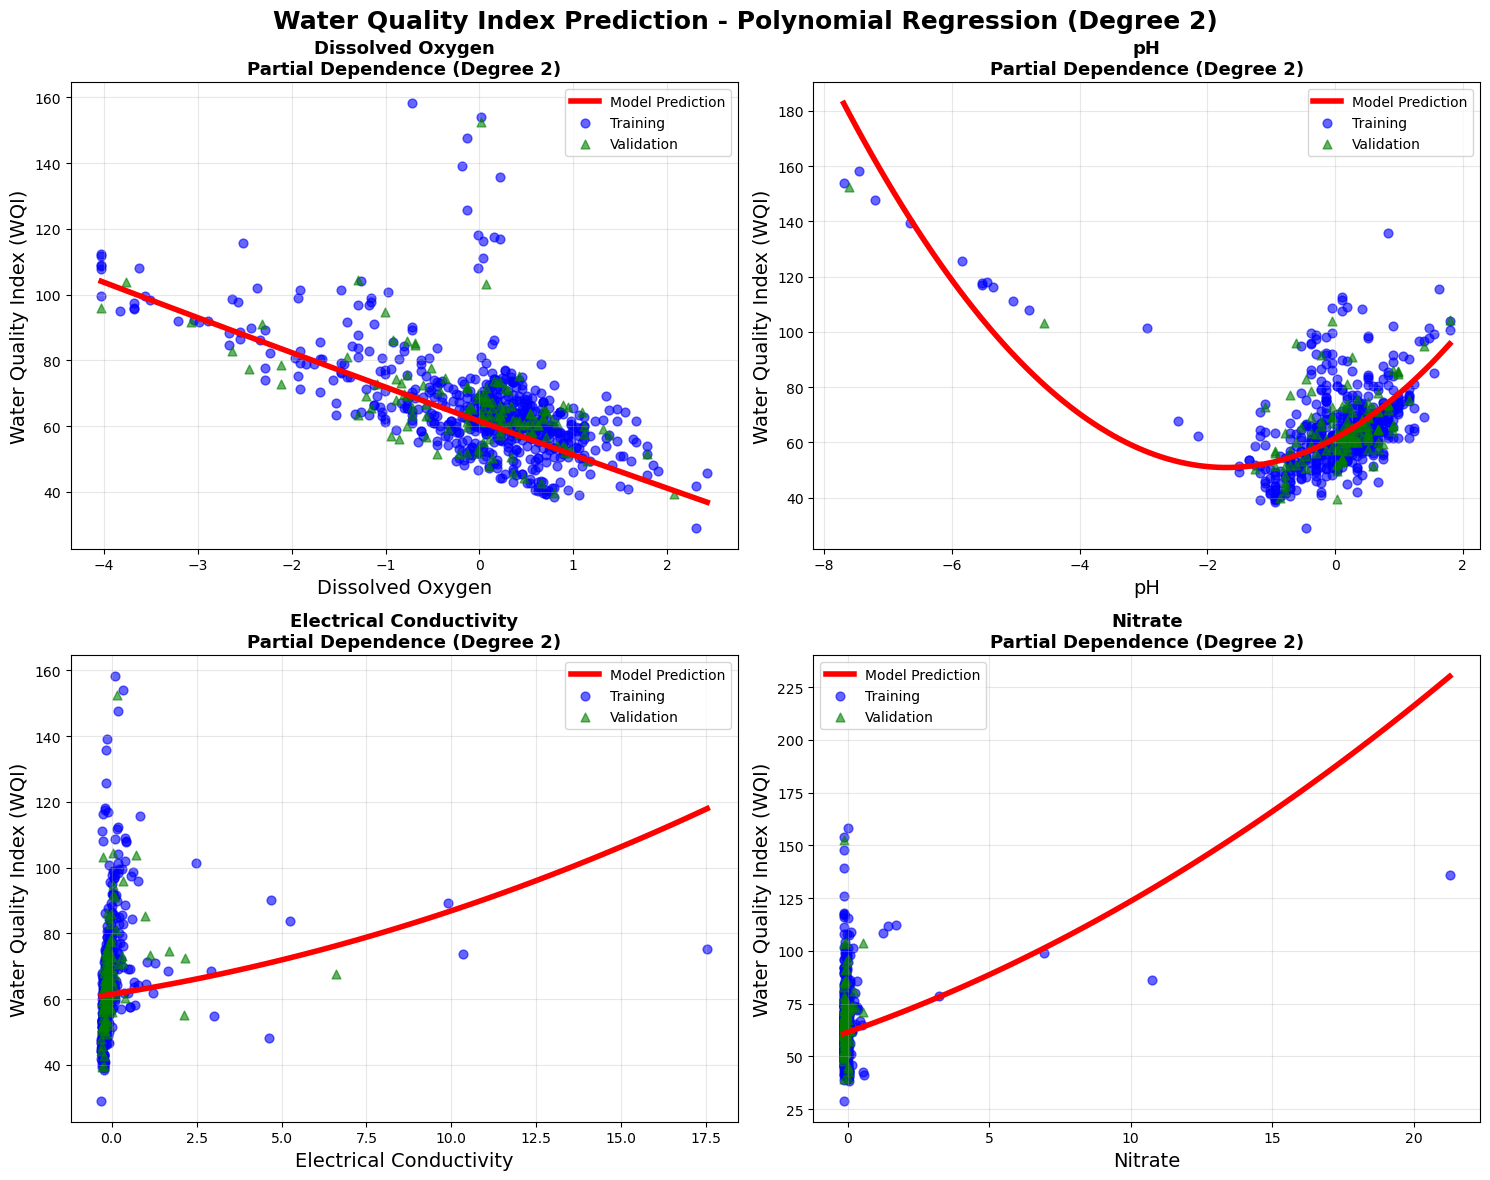

In [49]:
feature_names = ["Dissolved Oxygen", "pH", "Electrical Conductivity", "Nitrate"]

# Create a 2x2 subplot grid for all 4 features
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.ravel()  # Flatten for easy indexing

# Loop through each of your 4 features
for feature_idx in range(4):
    ax = axes[feature_idx]
    
    # Create grid for this specific feature
    feat_min, feat_max = x_train[:, feature_idx].min(), x_train[:, feature_idx].max()
    x_grid = np.linspace(feat_min, feat_max, 100).reshape(-1, 1)
    n_samples = len(x_grid)
    
    # Create full feature grid: fix all other features at their means
    x_means = np.mean(x_train, axis=0)
    X_grid = np.tile(x_means, (n_samples, 1))
    X_grid[:, feature_idx] = x_grid.flatten()
    
    # Transform through polynomial features and predict
    X_grid_poly = poly2.transform(X_grid)
    y_grid_pred = lr_poly2.predict(X_grid_poly)
    
    # Plot the partial dependence curve
    ax.plot(x_grid, y_grid_pred, 'r-', linewidth=4, label='Model Prediction')
    
    # Overlay actual data points for this feature
    ax.scatter(x_train[:, feature_idx], y_train, alpha=0.6, s=40, color='blue', label='Training')
    ax.scatter(x_val[:, feature_idx], y_val, alpha=0.6, s=40, marker='^', color='green', label='Validation')
    
    ax.set_xlabel(feature_names[feature_idx], fontsize=14)
    ax.set_ylabel('Water Quality Index (WQI)', fontsize=14)
    ax.set_title(f'{feature_names[feature_idx]}\nPartial Dependence (Degree 2)', 
                fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=10)

plt.suptitle('Water Quality Index Prediction - Polynomial Regression (Degree 2)', 
             fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


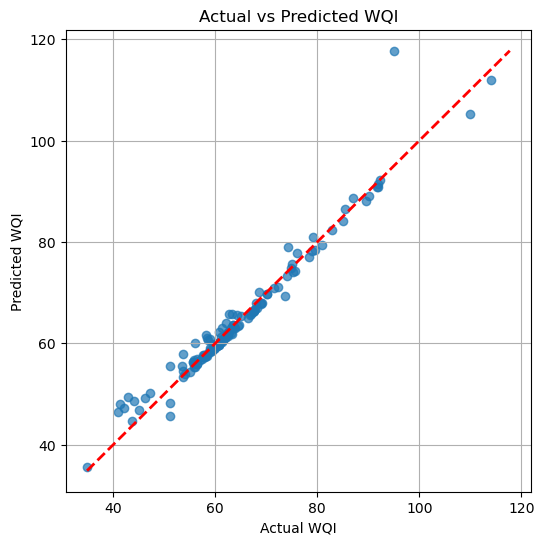

In [50]:
plt.figure(figsize=(6,6))

# Scatter plot
plt.scatter(y_test, y_test_pred2, alpha=0.7)

# Perfect prediction line (45°)
min_val = min(y_test.min(), y_test_pred2.min())
max_val = max(y_test.max(), y_test_pred2.max())

plt.plot([min_val, max_val],
         [min_val, max_val],
         'r--', linewidth=2)

plt.title("Actual vs Predicted WQI")
plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.grid(True)

plt.show()

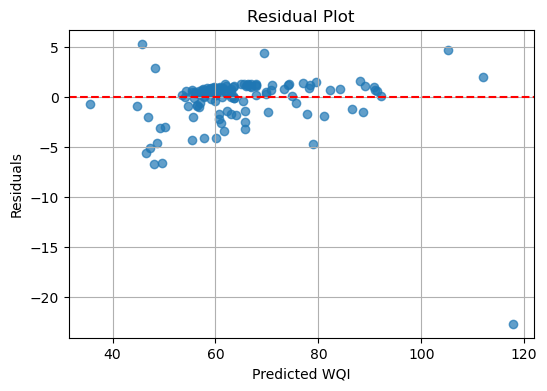

In [51]:
# Residuals = Actual - Predicted
residuals = y_test - y_test_pred2

# Residual plot
plt.figure(figsize=(6,4))
plt.scatter(y_test_pred2, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot")
plt.xlabel("Predicted WQI")
plt.ylabel("Residuals")
plt.grid(True)

plt.show()

## Conclusion

- Polynomial Regression improves the prediction of Water Quality Index over Linear Regression.
- Degree-2 polynomial captures non-linear relationships while avoiding unnecessary complexity.
- The model is evaluated using the R² score on train, validation, and test datasets.
- This project demonstrates an end-to-end machine learning workflow including preprocessing, feature engineering, model training, and evaluation.
